In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score, accuracy_score, roc_curve, auc
import random
import pandas as pd


In [2]:
GENERATIONS = 20
POPULATION_SIZE = 50
MUTATION_RATE = 0.05
INDPB_FEATURE = 0.02
CV_FOLDS = 5
ALPHA = 0.02
WEIGHT_AUC = 0.7
WEIGHT_ACC = 0.3
RANDOM_STATE = 42

np.random.seed(RANDOM_STATE)
random.seed(RANDOM_STATE)

In [3]:
data = load_breast_cancer()
X, y = data.data, data.target
feature_names = data.feature_names
n_features = X.shape[1]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y)

In [4]:
base_clf = RandomForestClassifier(random_state=RANDOM_STATE)
cv = StratifiedKFold(n_splits=CV_FOLDS, shuffle=True, random_state=RANDOM_STATE)
base_auc = cross_val_score(base_clf, X_train, y_train, cv=cv, scoring="roc_auc", n_jobs=-1).mean()
base_acc = cross_val_score(base_clf, X_train, y_train, cv=cv, scoring="accuracy", n_jobs=-1).mean()
print(f"Baseline (all features) CV AUC={base_auc:.4f}, CV Acc={base_acc:.4f}")

Baseline (all features) CV AUC=0.9896, CV Acc=0.9626


In [5]:
HP_BOUNDS = {
    "n_estimators": (50, 500),
    "max_depth": (1, 30),
    "min_samples_split": (2, 20),
    "min_samples_leaf": (1, 20),
    "max_features": (0.1, 1.0)
}
HYPERPARAM_COUNT = len(HP_BOUNDS)

def random_hyperparams():
    return [
        random.randint(*HP_BOUNDS["n_estimators"]),
        random.randint(*HP_BOUNDS["max_depth"]),
        random.randint(*HP_BOUNDS["min_samples_split"]),
        random.randint(*HP_BOUNDS["min_samples_leaf"]),
        round(random.uniform(*HP_BOUNDS["max_features"]), 3)
    ]

def create_individual():
    bits = np.random.randint(2, size=n_features).tolist()
    return np.array(bits + random_hyperparams(), dtype=object)

def decode_individual(ind):
    mask = np.array(ind[:n_features], dtype=int).astype(bool)
    hv = ind[n_features:]
    params = {"n_estimators": int(hv[0]), "max_depth": int(hv[1]) if int(hv[1])>0 else None,
              "min_samples_split": int(hv[2]), "min_samples_leaf": int(hv[3]),
              "max_features": float(hv[4])}
    return mask, params

In [6]:
def fitness(ind):
    mask, params = decode_individual(ind)
    if mask.sum() == 0:
        return 0.0
    Xs = X_train[:, mask]
    clf = RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1, **params)
    cv = StratifiedKFold(n_splits=CV_FOLDS, shuffle=True, random_state=RANDOM_STATE)
    try:
        aucs = cross_val_score(clf, Xs, y_train, cv=cv, scoring="roc_auc", n_jobs=1)
        accs = cross_val_score(clf, Xs, y_train, cv=cv, scoring="accuracy", n_jobs=1)
        mauc, macc = aucs.mean(), accs.mean()
    except Exception:
        mauc, macc = 0.0, 0.0
    penalty = ALPHA * (mask.sum() / n_features)
    return WEIGHT_AUC * mauc + WEIGHT_ACC * macc - penalty

In [7]:
def tournament_selection(pop, fits, k=3):
    idxs = np.random.choice(len(pop), k, replace=False)
    best = idxs[0]
    for i in idxs:
        if fits[i] > fits[best]:
            best = i
    return pop[best].copy()




In [8]:
def two_point_crossover(p1, p2):
    size = len(p1)
    a, b = sorted(random.sample(range(size), 2))
    c1 = np.concatenate((p1[:a], p2[a:b], p1[b:]))
    c2 = np.concatenate((p2[:a], p1[a:b], p2[b:]))
    return c1.copy(), c2.copy()

In [9]:
def mutate(ind):
    for i in range(n_features):
        if random.random() < INDPB_FEATURE:
            ind[i] = 1 - int(ind[i])
    if random.random() < 0.1:
        ind[n_features+0] = int(np.clip(int(ind[n_features+0]) + random.randint(-50,50), *HP_BOUNDS["n_estimators"]))
    if random.random() < 0.1:
        ind[n_features+1] = int(np.clip(int(ind[n_features+1]) + random.randint(-3,3), *HP_BOUNDS["max_depth"]))
    if random.random() < 0.1:
        ind[n_features+2] = int(np.clip(int(ind[n_features+2]) + random.randint(-2,2), *HP_BOUNDS["min_samples_split"]))
    if random.random() < 0.1:
        ind[n_features+3] = int(np.clip(int(ind[n_features+3]) + random.randint(-2,2), *HP_BOUNDS["min_samples_leaf"]))
    if random.random() < 0.15:
        ind[n_features+4] = float(np.clip(float(ind[n_features+4]) + random.uniform(-0.1,0.1), *HP_BOUNDS["max_features"]))
    return ind

In [10]:
population = [create_individual() for _ in range(POPULATION_SIZE)]
fitnesses = np.array([fitness(ind) for ind in population], dtype=float)
best_fitness_history = []
avg_fitness_history = []
best_num_features_history = []

for gen in range(GENERATIONS):
    new_pop = []
    elite_idx = np.argsort(fitnesses)[-2:]
    elites = [population[i].copy() for i in elite_idx]
    while len(new_pop) < POPULATION_SIZE - len(elites):
        p1 = tournament_selection(population, fitnesses)
        p2 = tournament_selection(population, fitnesses)
        if random.random() < 0.9:
            c1, c2 = two_point_crossover(p1, p2)
        else:
            c1, c2 = p1.copy(), p2.copy()
        if random.random() < MUTATION_RATE:
            c1 = mutate(c1)
        if random.random() < MUTATION_RATE:
            c2 = mutate(c2)
        new_pop.append(c1)
        if len(new_pop) < POPULATION_SIZE - len(elites):
            new_pop.append(c2)
    new_pop.extend(elites)
    population = new_pop
    fitnesses = np.array([fitness(ind) for ind in population], dtype=float)
    best_idx = np.argmax(fitnesses)
    best_fit = fitnesses[best_idx]
    best_mask, best_params = decode_individual(population[best_idx])
    best_fitness_history.append(best_fit)
    avg_fitness_history.append(fitnesses.mean())
    best_num_features_history.append(best_mask.sum())
    if (gen+1) % 5 == 0 or gen==0:
        print(f"Gen {gen+1}: best_fit={best_fit:.4f}, num_features={best_mask.sum()}, params={best_params}")

Gen 1: best_fit=0.9733, num_features=13, params={'n_estimators': 281, 'max_depth': 4, 'min_samples_split': 9, 'min_samples_leaf': 8, 'max_features': 0.158}
Gen 5: best_fit=0.9795, num_features=11, params={'n_estimators': 492, 'max_depth': 24, 'min_samples_split': 3, 'min_samples_leaf': 4, 'max_features': 0.155}
Gen 10: best_fit=0.9836, num_features=11, params={'n_estimators': 492, 'max_depth': 24, 'min_samples_split': 3, 'min_samples_leaf': 4, 'max_features': 0.155}
Gen 15: best_fit=0.9845, num_features=9, params={'n_estimators': 474, 'max_depth': 24, 'min_samples_split': 3, 'min_samples_leaf': 4, 'max_features': 0.155}
Gen 20: best_fit=0.9845, num_features=9, params={'n_estimators': 474, 'max_depth': 24, 'min_samples_split': 3, 'min_samples_leaf': 4, 'max_features': 0.155}


In [11]:
best_ind = population[np.argmax(fitnesses)]
mask, params = decode_individual(best_ind)
selected_names = [n for n,m in zip(feature_names, mask) if m]

final_clf = RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1, **params)
final_clf.fit(X_train[:, mask], y_train)
y_proba = final_clf.predict_proba(X_test[:, mask])[:,1]
y_pred = final_clf.predict(X_test[:, mask])
final_auc = roc_auc_score(y_test, y_proba)
final_acc = accuracy_score(y_test, y_pred)

In [12]:
all_clf = RandomForestClassifier(random_state=RANDOM_STATE)
all_clf.fit(X_train, y_train)
all_auc = roc_auc_score(y_test, all_clf.predict_proba(X_test)[:,1])
all_acc = accuracy_score(y_test, all_clf.predict(X_test))

print("\nRESULTS:")
print("Selected features count:", mask.sum())
print("Selected feature names:", selected_names)
print("Best hyperparams:", params)
print(f"Final test AUC: {final_auc:.4f}, Accuracy: {final_acc:.4f}")
print(f"All-features test AUC: {all_auc:.4f}, Accuracy: {all_acc:.4f}")


RESULTS:
Selected features count: 9
Selected feature names: [np.str_('mean texture'), np.str_('mean concave points'), np.str_('mean symmetry'), np.str_('mean fractal dimension'), np.str_('area error'), np.str_('worst texture'), np.str_('worst area'), np.str_('worst smoothness'), np.str_('worst concavity')]
Best hyperparams: {'n_estimators': 474, 'max_depth': 24, 'min_samples_split': 3, 'min_samples_leaf': 4, 'max_features': 0.155}
Final test AUC: 0.9937, Accuracy: 0.9825
All-features test AUC: 0.9937, Accuracy: 0.9561


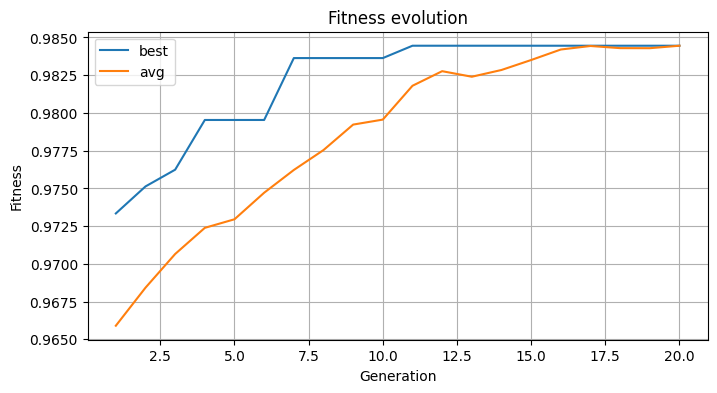

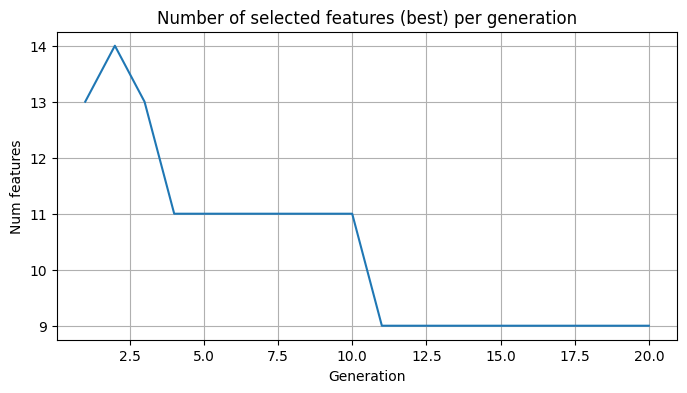

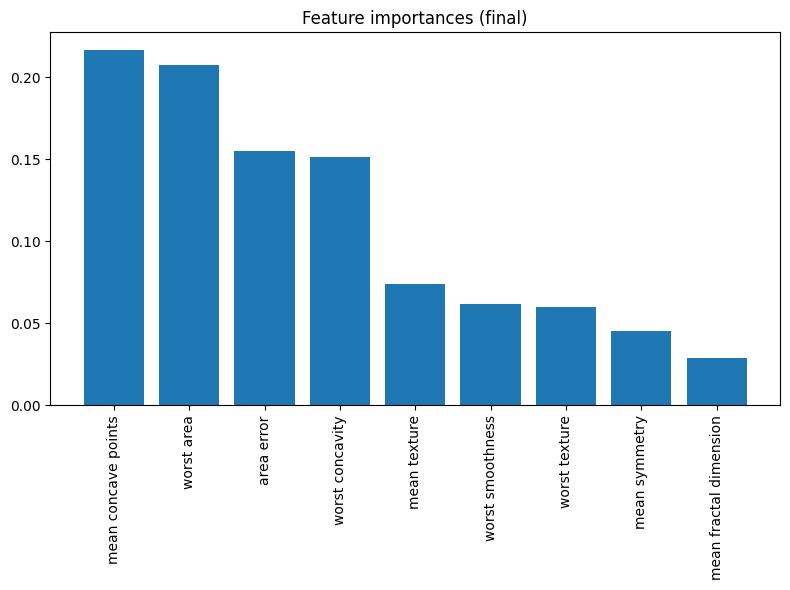

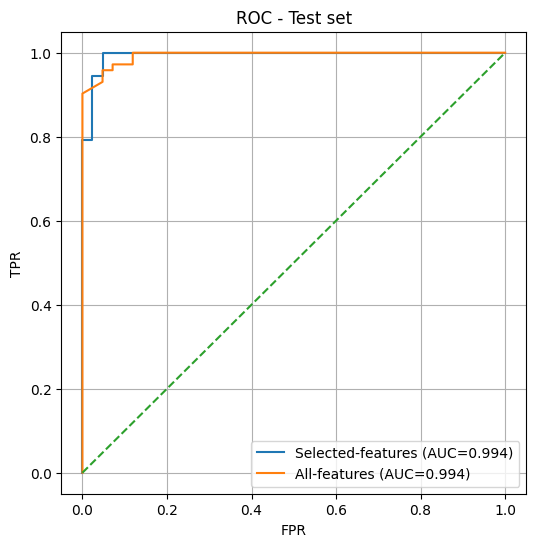

In [13]:
plt.figure(figsize=(8,4))
plt.plot(range(1, GENERATIONS+1), best_fitness_history, label='best')
plt.plot(range(1, GENERATIONS+1), avg_fitness_history, label='avg')
plt.title('Fitness evolution')
plt.xlabel('Generation'); plt.ylabel('Fitness'); plt.legend(); plt.grid(True); plt.show()

plt.figure(figsize=(8,4))
plt.plot(range(1, GENERATIONS+1), best_num_features_history)
plt.title('Number of selected features (best) per generation')
plt.xlabel('Generation'); plt.ylabel('Num features'); plt.grid(True); plt.show()

importances = final_clf.feature_importances_
order = np.argsort(importances)[::-1]
names_sorted = np.array(selected_names)[order]
vals_sorted = importances[order]
plt.figure(figsize=(8,6))
plt.bar(range(len(vals_sorted)), vals_sorted)
plt.xticks(range(len(vals_sorted)), names_sorted, rotation=90)
plt.title('Feature importances (final)'); plt.tight_layout(); plt.show()

fpr, tpr, _ = roc_curve(y_test, y_proba)
fpr2, tpr2, _ = roc_curve(y_test, all_clf.predict_proba(X_test)[:,1])
plt.figure(figsize=(6,6))
plt.plot(fpr, tpr, label=f"Selected-features (AUC={auc(fpr,tpr):.3f})")
plt.plot(fpr2, tpr2, label=f"All-features (AUC={auc(fpr2,tpr2):.3f})")
plt.plot([0,1],[0,1],'--'); plt.xlabel('FPR'); plt.ylabel('TPR'); plt.title('ROC - Test set'); plt.legend(); plt.grid(True); plt.show()

In [14]:
summary = pd.DataFrame({
    "Model":["Baseline CV (train, all)","All-features (test)","Selected-features (test)"],
    "CV_AUC":[base_auc, None, None],
    "CV_Acc":[base_acc, None, None],
    "Test_AUC":[None, all_auc, final_auc],
    "Test_Acc":[None, all_acc, final_acc],
    "Num_features":[n_features, n_features, int(mask.sum())]
})
print("\nSummary:\n", summary)


Summary:
                       Model    CV_AUC    CV_Acc  Test_AUC  Test_Acc  \
0  Baseline CV (train, all)  0.989577  0.962637       NaN       NaN   
1       All-features (test)       NaN       NaN  0.993717  0.956140   
2  Selected-features (test)       NaN       NaN  0.993717  0.982456   

   Num_features  
0            30  
1            30  
2             9  
